<a href="https://colab.research.google.com/github/miso88oup/image-caption-generator/blob/main/notebooks/01_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Caption Generator — Data Preprocessing

Dataset: Flickr8k (8,091 images, 5 captions per image)

## 1. Setup

In [1]:
import os
import re
import json
import random
from collections import defaultdict, Counter

import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/image-caption-project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

Mounted at /content/drive


## 2. Load Dataset

In [2]:
import kagglehub

DATASET_PATH = kagglehub.dataset_download('adityajn105/flickr8k')
IMAGE_DIR = os.path.join(DATASET_PATH, 'Images')
CAPTIONS_FILE = os.path.join(DATASET_PATH, 'captions.txt')

print('Images:', len(os.listdir(IMAGE_DIR)))

100%|██████████| 1.04G/1.04G [00:07<00:00, 145MB/s]

Extracting files...


Images: 8091


In [3]:
captions = defaultdict(list)

with open(CAPTIONS_FILE, encoding='utf-8') as f:
    next(f)  # header
    for line in f:
        line = line.strip()
        if not line:
            continue
        image_name, caption = line.split(',', 1)
        captions[image_name].append(caption.strip().strip('"'))

print('Images:', len(captions))
print('Captions:', sum(len(c) for c in captions.values()))

example = list(captions.keys())[0]
captions[example]

Images: 8091
Captions: 40455


['A child in a pink dress is climbing up a set of stairs in an entry way .',
 'A girl going into a wooden building .',
 'A little girl climbing into a wooden playhouse .',
 'A little girl climbing the stairs to her playhouse .',
 'A little girl in a pink dress going into a wooden cabin .']

## 3. Caption Cleaning

Lowercase, remove punctuation and numbers, drop single characters (except "a"), and add `startseq` / `endseq` tokens.

In [4]:
def clean_caption(text):
    text = text.lower()
    text = re.sub(r'[^a-z ]', ' ', text)
    words = [w for w in text.split() if len(w) > 1 or w == 'a']
    return 'startseq ' + ' '.join(words) + ' endseq'

clean_captions = {img: [clean_caption(c) for c in caps] for img, caps in captions.items()}

print(captions[example][0])
print(clean_captions[example][0])

A child in a pink dress is climbing up a set of stairs in an entry way .
startseq a child in a pink dress is climbing up a set of stairs in an entry way endseq


## 4. Train / Validation / Test Split

Split by image (6000 / 1000 / 1091) to avoid leakage between sets.

In [5]:
all_images = sorted(clean_captions.keys())

random.seed(42)
random.shuffle(all_images)

train_images = all_images[:6000]
val_images = all_images[6000:7000]
test_images = all_images[7000:]

print(len(train_images), len(val_images), len(test_images))

6000 1000 1091


## 5. Vocabulary

Built from training captions only. Words with frequency < 5 are mapped to `<unk>`.

In [6]:
MIN_COUNT = 5

word_counts = Counter()
for img in train_images:
    for cap in clean_captions[img]:
        word_counts.update(cap.split())

vocab = sorted(w for w, c in word_counts.items() if c >= MIN_COUNT)

word2idx = {'<pad>': 0, '<unk>': 1}
for w in vocab:
    word2idx[w] = len(word2idx)
idx2word = {i: w for w, i in word2idx.items()}

vocab_size = len(word2idx)
max_length = max(len(c.split()) for img in train_images for c in clean_captions[img])

print('Vocabulary size:', vocab_size)
print('Max caption length:', max_length)

Vocabulary size: 2559
Max caption length: 38


In [7]:
def encode(caption):
    return [word2idx.get(w, 1) for w in caption.split()]

def decode(ids):
    return ' '.join(idx2word[i] for i in ids if i != 0)

sample = clean_captions[example][0]
print(encode(sample))
print(decode(encode(sample)))

[2117, 2, 427, 1090, 2, 1595, 643, 1119, 459, 2419, 2, 1883, 1439, 2102, 1090, 44, 1, 2486, 705]
startseq a child in a pink dress is climbing up a set of stairs in an <unk> way endseq


## 6. Data Exploration

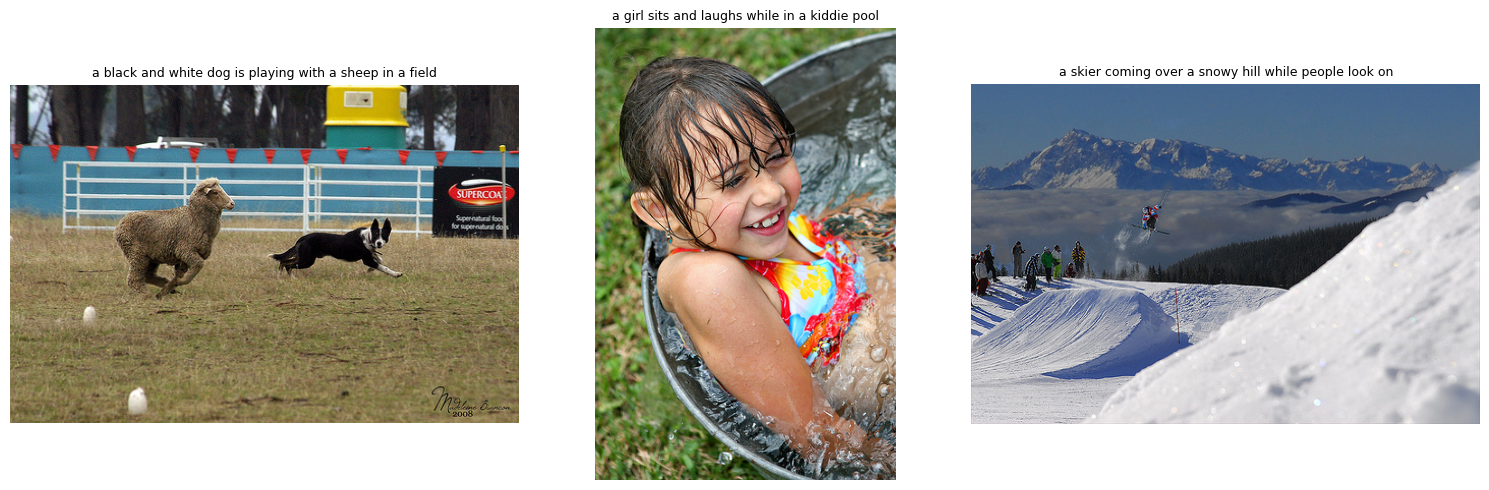

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img in zip(axes, train_images[:3]):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, img)))
    ax.set_title(clean_captions[img][0][9:-7], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sample_images.png'), dpi=150, bbox_inches='tight')
plt.show()

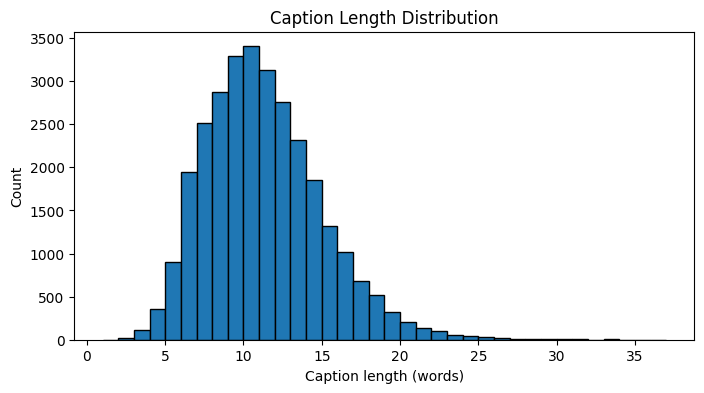

In [9]:
lengths = [len(c.split()) - 2 for img in train_images for c in clean_captions[img]]

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=range(1, max(lengths) + 2), edgecolor='black')
plt.xlabel('Caption length (words)')
plt.ylabel('Count')
plt.title('Caption Length Distribution')
plt.savefig(os.path.join(RESULTS_DIR, 'caption_lengths.png'), dpi=150, bbox_inches='tight')
plt.show()

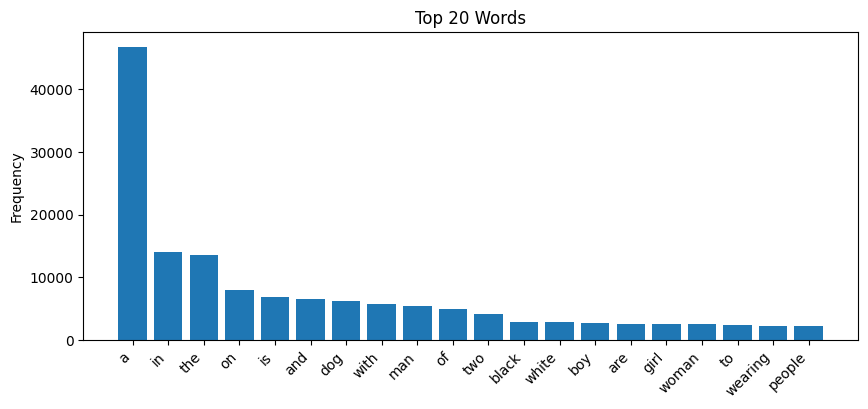

In [10]:
top = [(w, c) for w, c in word_counts.most_common(22) if w not in ('startseq', 'endseq')][:20]
words, counts = zip(*top)

plt.figure(figsize=(10, 4))
plt.bar(words, counts)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Frequency')
plt.title('Top 20 Words')
plt.savefig(os.path.join(RESULTS_DIR, 'top_words.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Save

In [11]:
with open(os.path.join(DATA_DIR, 'captions_clean.json'), 'w') as f:
    json.dump(clean_captions, f)

with open(os.path.join(DATA_DIR, 'splits.json'), 'w') as f:
    json.dump({'train': train_images, 'val': val_images, 'test': test_images}, f)

with open(os.path.join(DATA_DIR, 'vocab.json'), 'w') as f:
    json.dump({'word2idx': word2idx, 'vocab_size': vocab_size, 'max_length': max_length}, f)

os.listdir(DATA_DIR)

['captions_clean.json', 'splits.json', 'vocab.json']